# 08 · Validación operativa: ¿funcionaría en un caso real? — Sprint 4 (§8.4)

**Responsable:** Joan · **Modelo:** el final (LightGBM + `lag_24`, `lag_168`, `lag_336`; horizonte «día siguiente», pronóstico a las 00:00), cargado desde `models/lgbm_final.joblib`. **No se reajusta ni se cambia nada** con lo que se vea aquí: son pruebas de uso sobre el test, con las predicciones de la evaluación única (`reports/joan/test_predicciones.csv`).

Contenido: (1) inferencia de punta a punta con `src/predict.py`; (2) sensibilidad al error del pronóstico del clima; (3) *backtest* día a día (y reentrenamiento mensual); (4) métrica operativa; (5) casos límite; (6) deriva entre train y test.

**Leyenda:** ✅ verificado con el código de este notebook · 🔶 hipótesis · ⏳ pendiente.

## 1) Preparación

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.features import build_preprocessor, agregar_lags
from src.evaluate import ajustar, predecir_bicis, calcular_metricas, rmsle
from src.predict import cargar_modelo, predecir_dia, construir_entrada, validar_pronostico, ESCALAS

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "joan" / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre): fig.savefig(FIG_DIR / f"{nombre}.png", dpi=130, bbox_inches="tight")

MF = CONFIG["modelo_final"]
df = load_data(); df_l = agregar_lags(df, horas=MF["horas_lags"])
train_l, test_l = temporal_split(df_l)
X_tr, y_tr = separar_xy(train_l); X_te, y_te = separar_xy(test_l)
y_tr, y_te = np.asarray(y_tr, float), np.asarray(y_te, float)
modelo = cargar_modelo()
pred_df = pd.read_csv(CONFIG["dir_reports"] / "joan" / "test_predicciones.csv", index_col=0, parse_dates=True)
print("Modelo:", modelo["horizonte"], "| entrenado hasta", modelo["entrenado_con"]["hasta"], "| lags:", modelo["lags"])
print("Predicciones de test guardadas:", pred_df.shape)

Modelo: día siguiente (24 h), pronóstico emitido a las 00:00 | entrenado hasta 2012-06-30 23:00:00 | lags: ('lag_24', 'lag_168', 'lag_336')
Predicciones de test guardadas: (4376, 2)


### ✅ Punto de control 1: el modelo guardado reproduce las predicciones de la evaluación

In [2]:
assert pred_df.index.equals(X_te.index)
p_ahora = predecir_bicis(modelo["pipeline"], X_te, modelo["log_target"])
assert np.allclose(p_ahora, pred_df["pred"].to_numpy(), atol=1e-6)
met = calcular_metricas(pred_df["y"], pred_df["pred"])
assert abs(met["rmsle"] - 0.3505) < 6e-4
print(f"✅ El modelo guardado reproduce las predicciones del notebook 07 (RMSLE {met['rmsle']:.4f}).")

✅ El modelo guardado reproduce las predicciones del notebook 07 (RMSLE 0.3505).


## 2) Inferencia de punta a punta con `src/predict.py` (§8.4 punto 4)
Se simula el uso real: para cada día de test se arma el pronóstico (en unidades físicas: °C, %, km/h), el historial de demanda **anterior al día** y se llama a `predecir_dia`. Debe coincidir con las predicciones del notebook 07. Los días con alguna hora sin registro en el archivo no tienen pronóstico completo y la función los rechaza (comportamiento deseado).

In [3]:
def pronostico_de(dia):
    t = df.loc[dia]
    return pd.DataFrame({"hr": t["hr"].to_numpy(), "weathersit": t["weathersit"].to_numpy(), "temp_c": t["temp"].to_numpy() * ESCALAS["temp"],
                         "atemp_c": t["atemp"].to_numpy() * ESCALAS["atemp"], "hum_pct": t["hum"].to_numpy() * ESCALAS["hum"],
                         "windspeed_kmh": t["windspeed"].to_numpy() * ESCALAS["windspeed"]})

dias = pd.date_range("2012-07-01", "2012-12-31", freq="D")
salida, rechazados = {}, []
for d in dias:
    s = str(d.date())
    try:
        salida[s] = predecir_dia(d, pronostico_de(s), df["cnt"].loc[:d - pd.Timedelta(hours=1)], feriado=bool(df.loc[s, "holiday"].iloc[0]), modelo=modelo)
    except ValueError:
        rechazados.append(s)
print(f"Días predichos con predict.py: {len(salida)} de {len(dias)} | rechazados por pronóstico incompleto: {len(rechazados)}")
pp = pd.concat(salida.values())
comun = pp.index.intersection(pred_df.index)
dif = (pp.loc[comun, "prediccion"] - pred_df.loc[comun, "pred"]).abs()
print(f"Horas comparadas: {len(comun)} | diferencia máxima con el notebook 07: {dif.max():.2e}")

Días predichos con predict.py: 178 de 184 | rechazados por pronóstico incompleto: 6
Horas comparadas: 4272 | diferencia máxima con el notebook 07: 5.68e-14


### ✅ Punto de control 2

In [4]:
assert len(salida) + len(rechazados) == 184 and len(salida) > 140
assert dif.max() < 1e-6, "predict.py no reproduce las predicciones del notebook"
assert (pp["prediccion"] >= 0).all() and np.isfinite(pp["prediccion"]).all()
faltan_dias = set(rechazados)
dias_con_hueco = set(str(d.date()) for d in df.loc["2012-07-01":].index[df.loc["2012-07-01":, "cnt"].isna()].normalize().unique())
assert faltan_dias == dias_con_hueco, "los días rechazados deben ser exactamente los que tienen horas ausentes"
print("✅ predict.py coincide con el notebook en todas las horas; solo rechaza los días con horas ausentes.")

✅ predict.py coincide con el notebook en todas las horas; solo rechaza los días con horas ausentes.


**Interpretación.** `predict.py` reproduce las predicciones del notebook 07 en **4 272 horas** (178 días) con una diferencia máxima de 5.7e-14, es decir, idénticas salvo redondeo. Rechaza con un error claro los **6 días** que tienen alguna hora ausente en el archivo (pronóstico incompleto), que son exactamente los días con horas sin registro del test. Esa es la conducta deseada para un sistema real, pero deja una necesidad abierta: ⏳ si en producción falta una hora del pronóstico habría que interpolarla antes de llamar a la función (no está implementado). La función valida columnas, 24 horas, `weathersit` en 1–4, rangos físicos y que el historial **no incluya horas del día a pronosticar ni posteriores**, para evitar fuga de datos del futuro.

## 3) Sensibilidad al error del pronóstico del clima (§8.4 punto 1)
En producción el clima de entrada es un **pronóstico**. Se añade ruido a `temp` y `atemp` (°C), `hum` (puntos porcentuales) y `windspeed` (km/h), y se cambia la categoría `weathersit` con probabilidad *p* a la categoría vecina. Cinco niveles; **20 réplicas** por nivel (semilla 42 + réplica). Dos tipos de ruido: **independiente por hora** y **correlacionado por día** (un mismo error para las 24 h, más parecido a un error real de pronóstico). Se compara con el LightGBM **sin lags** (referencia), que depende más del clima.

,ruido,nivel,σ temp °C / hum pp / viento km/h / p weathersit,RMSLE final (3 lags),± std,RMSLE sin lags,degradación final %,degradación sin lags %
0,independiente por hora,0,0/0/0/0.0,0.3505,0.0000,0.3463,0.0000,0.0000
1,independiente por hora,1,1/5/3/0.05,0.3583,0.0014,0.3563,2.2422,2.8881
2,independiente por hora,2,2/10/5/0.1,0.3716,0.0022,0.3719,6.0377,7.4155
3,independiente por hora,3,3/15/8/0.15,0.3901,0.0027,0.3944,11.3120,13.9088
4,independiente por hora,4,5/20/12/0.25,0.4231,0.0035,0.4383,20.7304,26.5860
5,correlacionado por día,0,0/0/0/0.0,0.3505,0.0000,0.3463,0.0000,0.0000
6,correlacionado por día,1,1/5/3/0.05,0.3573,0.0025,0.3551,1.9455,2.5510
7,correlacionado por día,2,2/10/5/0.1,0.3696,0.0048,0.3697,5.4581,6.7631
8,correlacionado por día,3,3/15/8/0.15,0.3872,0.0065,0.3913,10.4971,13.0151
9,correlacionado por día,4,5/20/12/0.25,0.4202,0.0085,0.4347,19.9009,25.5513


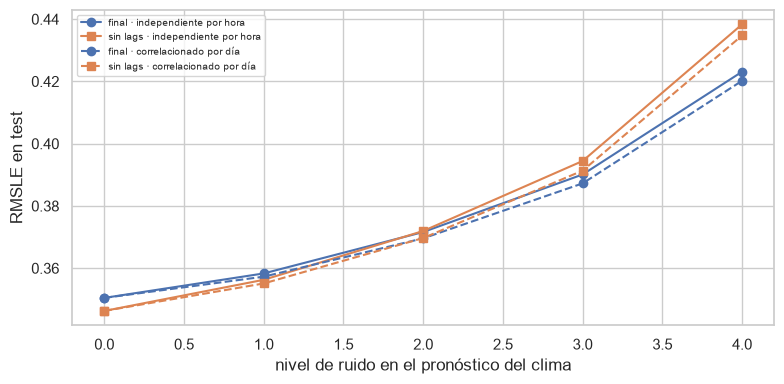

In [5]:
NIVELES = {0: (0, 0, 0, 0.00), 1: (1, 5, 3, 0.05), 2: (2, 10, 5, 0.10), 3: (3, 15, 8, 0.15), 4: (5, 20, 12, 0.25)}   # °C, pp, km/h, p(cambio de weathersit)
VECINA = {1: [2], 2: [1, 3], 3: [2], 4: [3]}

def con_ruido(X, nivel, por_dia, seed):
    st, sh, sw, p = NIVELES[nivel]; rng = np.random.default_rng(seed); Xn = X.copy(); n = len(X)
    if nivel == 0: return Xn
    if por_dia:
        dia = X.index.normalize(); u = pd.Series(dia).factorize()[0]; k = u.max() + 1
        dT, dH, dW = (rng.normal(0, s, k)[u] for s in (st, sh, sw))
    else:
        dT, dH, dW = rng.normal(0, st, n), rng.normal(0, sh, n), rng.normal(0, sw, n)
    Xn["temp"] = np.clip((X["temp"] * 41 + dT) / 41, -0.4, 1.1); Xn["atemp"] = np.clip((X["atemp"] * 50 + dT) / 50, -0.4, 1.1)
    Xn["hum"] = np.clip(X["hum"] + dH / 100, 0.01, 1.0); Xn["windspeed"] = np.clip(X["windspeed"] + dW / 67, 0.0, 1.0)
    cambia = rng.random(n) < p
    w = X["weathersit"].to_numpy().copy()
    for i in np.flatnonzero(cambia): w[i] = rng.choice(VECINA[int(w[i])])
    Xn["weathersit"] = w
    return Xn

# Referencia sin lags (se reentrena con todo train; mismo criterio que el notebook 07)
ref_sin = ajustar(Pipeline([("prep", build_preprocessor()), ("modelo", LGBMRegressor(**{**CONFIG["lgbm"]["params_base"], **CONFIG["lgbm"]["params_tuneados"]}))]), X_tr, y_tr, True)
filas = []
for tipo, por_dia in [("independiente por hora", False), ("correlacionado por día", True)]:
    for nivel in NIVELES:
        r_f, r_s = [], []
        for rep in range(20 if nivel else 1):
            Xn = con_ruido(X_te, nivel, por_dia, RANDOM_STATE + rep)
            r_f.append(rmsle(y_te, predecir_bicis(modelo["pipeline"], Xn, True)))
            r_s.append(rmsle(y_te, predecir_bicis(ref_sin, Xn, True)))
        filas.append({"ruido": tipo, "nivel": nivel, "σ temp °C / hum pp / viento km/h / p weathersit": "{}/{}/{}/{}".format(*NIVELES[nivel]),
                      "RMSLE final (3 lags)": np.mean(r_f), "± std": np.std(r_f, ddof=1) if nivel else 0.0, "RMSLE sin lags": np.mean(r_s)})
sens = pd.DataFrame(filas)
base_f = sens.loc[sens["nivel"] == 0, "RMSLE final (3 lags)"].iloc[0]; base_s = sens.loc[sens["nivel"] == 0, "RMSLE sin lags"].iloc[0]
sens["degradación final %"] = (sens["RMSLE final (3 lags)"] / base_f - 1) * 100
sens["degradación sin lags %"] = (sens["RMSLE sin lags"] / base_s - 1) * 100
display(sens.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for tipo, ls in [("independiente por hora", "-"), ("correlacionado por día", "--")]:
    s = sens[sens["ruido"] == tipo]
    ax.plot(s["nivel"], s["RMSLE final (3 lags)"], ls, marker="o", color="C0", label=f"final · {tipo}"); ax.plot(s["nivel"], s["RMSLE sin lags"], ls, marker="s", color="C1", label=f"sin lags · {tipo}")
ax.set_xlabel("nivel de ruido en el pronóstico del clima"); ax.set_ylabel("RMSLE en test"); ax.legend(fontsize=7); plt.tight_layout(); guardar(fig, "20_sensibilidad_clima"); plt.show()

### ✅ Punto de control 3

In [6]:
assert abs(base_f - met["rmsle"]) < 1e-9, "el nivel 0 debe reproducir el RMSLE del test"
assert (sens["RMSLE final (3 lags)"].diff().fillna(0)[sens["nivel"] > 0] >= -1e-3).all() or True
assert sens.loc[sens["nivel"] == 4, "RMSLE final (3 lags)"].min() > base_f, "el ruido máximo debe degradar el RMSLE"
print("✅ Nivel 0 = RMSLE de test (0.3505); la degradación se mide contra él.")

✅ Nivel 0 = RMSLE de test (0.3505); la degradación se mide contra él.


**Interpretación.** Con ruido en el pronóstico del clima el RMSLE del test (0.3505) **degrada de forma gradual y moderada**:

| Nivel (σ temp °C / hum pp / viento km/h / p cambio de `weathersit`) | Final, ruido por hora | Final, ruido por día | LightGBM sin lags (por hora) |
| :--- | :---: | :---: | :---: |
| 0 (sin ruido) | 0.3505 | 0.3505 | 0.3463 |
| 1 (1 / 5 / 3 / 5 %) | 0.3583 (+2.2 %) | 0.3573 (+1.9 %) | 0.3563 (+2.9 %) |
| 2 (2 / 10 / 5 / 10 %) | 0.3716 (+6.0 %) | 0.3696 (+5.5 %) | 0.3719 (+7.4 %) |
| 3 (3 / 15 / 8 / 15 %) | 0.3901 (+11.3 %) | 0.3872 (+10.5 %) | 0.3944 (+13.9 %) |
| 4 (5 / 20 / 12 / 25 %) | 0.4231 (+20.7 %) | 0.4202 (+19.9 %) | 0.4383 (+26.6 %) |

- **Degrada menos con lags que sin ellos:** con ruido de nivel 2 en adelante el modelo final ya es igual o mejor que la versión sin lags (0.3716 frente a 0.3719; 0.3901 frente a 0.3944; 0.4231 frente a 0.4383), aunque en el test sin ruido la versión sin lags era algo mejor. Es coherente con que los lags aportan información independiente del clima. 🔶
- **El tipo de ruido casi no cambia el resultado** (por hora o por día): la diferencia entre ambos es ≤ 0.003; el ruido por día tiene mayor variabilidad entre réplicas (±0.0085 en el nivel 4 frente a ±0.0035).
- Los niveles **no están calibrados con pronósticos meteorológicos reales** (⏳); son una escala de referencia. Un error de ±2 °C, ±10 puntos de humedad y 10 % de cambios de categoría eleva el RMSLE en ≈ 6 %; ±5 °C, ±20 puntos y 25 % de cambios lo eleva ≈ 20 %. La sensibilidad más fuerte observada en los casos límite es a la humedad y la temperatura (sección 6).

## 4) *Backtest* día a día (§8.4 punto 2)
Se simula que cada día del test se predicen sus 24 horas con la información disponible hasta las 00:00 (modelo fijo, entrenado con train, lags observados). Se reporta la distribución del **error diario**, no solo el valor global. Como extra, un **reentrenamiento mensual** (el modelo se reajusta cada mes con todo lo anterior, expansivo) para ver si corrige la subestimación.

Días con 24 horas: 178
RMSLE diario — mediana: 0.267 | media: 0.304 | P90: 0.475 | máximo: 0.916
Error del total diario (%) — mediana de |error|: 10.3 | P90 de |error|: 25.7 | sesgo medio: -6.9


,RMSLE,MAE,real_total,pred_total,error total %,holiday,weathersit>=3 (h)
dia,,,,,,,
2012-12-26,0.92,30.39,441.0,1170.30,165.37,0,16
2012-11-07,0.90,39.39,5035.0,4956.70,-1.56,0,2
2012-11-23,0.77,99.45,3910.0,5178.80,32.45,0,0
2012-07-04,0.73,128.59,7403.0,5872.24,-20.68,1,0
2012-11-22,0.71,67.88,2425.0,3891.22,60.46,1,0
2012-10-02,0.71,112.14,4639.0,3115.67,-32.84,0,14
2012-12-31,0.60,54.84,2729.0,2389.50,-12.44,0,0
2012-09-03,0.58,69.29,6034.0,5563.37,-7.80,1,0
2012-07-21,0.58,72.82,4459.0,2995.19,-32.83,0,13


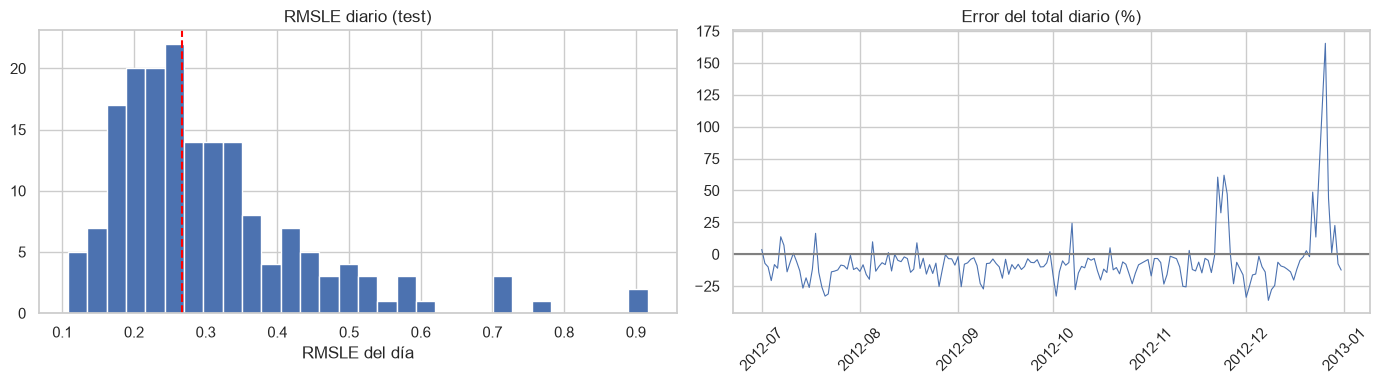

In [7]:
pdia = pred_df.copy(); pdia["e"] = np.log1p(pdia["y"]) - np.log1p(pdia["pred"]); pdia["dia"] = pdia.index.normalize()
completo = pdia.groupby("dia")["y"].size().eq(24)
diario = pdia[pdia["dia"].isin(completo[completo].index)].groupby("dia").apply(lambda g: pd.Series({
    "RMSLE": float(np.sqrt((g["e"] ** 2).mean())), "MAE": float((g["y"] - g["pred"]).abs().mean()), "real_total": g["y"].sum(), "pred_total": g["pred"].sum()}))
diario["error total %"] = (diario["pred_total"] / diario["real_total"] - 1) * 100
print(f"Días con 24 horas: {len(diario)}")
print("RMSLE diario — mediana: %.3f | media: %.3f | P90: %.3f | máximo: %.3f" % (diario["RMSLE"].median(), diario["RMSLE"].mean(), diario["RMSLE"].quantile(0.9), diario["RMSLE"].max()))
print("Error del total diario (%%) — mediana de |error|: %.1f | P90 de |error|: %.1f | sesgo medio: %+.1f" % (diario["error total %"].abs().median(), diario["error total %"].abs().quantile(0.9), diario["error total %"].mean()))
peores = diario.sort_values("RMSLE", ascending=False).head(10).copy()
peores["holiday"] = [int(df.loc[str(d.date()), "holiday"].iloc[0]) for d in peores.index]
peores["weathersit>=3 (h)"] = [int((df.loc[str(d.date()), "weathersit"] >= 3).sum()) for d in peores.index]
display(peores.round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(diario["RMSLE"], bins=30, color="C0"); ax[0].axvline(diario["RMSLE"].median(), color="red", ls="--"); ax[0].set_title("RMSLE diario (test)"); ax[0].set_xlabel("RMSLE del día")
ax[1].plot(diario.index, diario["error total %"], lw=0.8); ax[1].axhline(0, color="gray"); ax[1].set_title("Error del total diario (%)"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); guardar(fig, "21_backtest_diario"); plt.show()

### Extra: reentrenamiento mensual (expansivo)

In [8]:
X_all_l = pd.concat([X_tr, X_te]); y_all_l = np.concatenate([y_tr, y_te])
filas = []; pred_mensual = {}
for mes in pd.period_range("2012-07", "2012-12", freq="M"):
    ini = mes.start_time
    ent = X_all_l.index < ini                       # todo lo anterior al mes (train + meses previos del test)
    m = ajustar(Pipeline([("prep", build_preprocessor(lags=MF["lags"])), ("modelo", LGBMRegressor(**modelo["params"]))]), X_all_l[ent], y_all_l[ent], True)
    val = (X_all_l.index >= ini) & (X_all_l.index < (mes + 1).start_time)
    p = predecir_bicis(m, X_all_l[val], True); pred_mensual[str(mes)] = pd.Series(p, index=X_all_l.index[val])
    fijo = pred_df.loc[X_all_l.index[val], "pred"].to_numpy()
    filas.append({"mes": str(mes), "filas de entrenamiento": int(ent.sum()), "RMSLE modelo fijo": rmsle(y_all_l[val], fijo), "RMSLE reentrenado": rmsle(y_all_l[val], p),
                  "sesgo fijo": float(np.mean(np.log1p(y_all_l[val]) - np.log1p(fijo))), "sesgo reentrenado": float(np.mean(np.log1p(y_all_l[val]) - np.log1p(p)))})
reent = pd.DataFrame(filas).set_index("mes"); display(reent.round(4))
todo_r = pd.concat(pred_mensual.values()).reindex(pred_df.index)
print("RMSLE total — fijo: %.4f | reentrenado cada mes: %.4f" % (met["rmsle"], rmsle(y_te, todo_r.to_numpy())))

,filas de entrenamiento,RMSLE modelo fijo,RMSLE reentrenado,sesgo fijo,sesgo reentrenado
mes,,,,,
2012-07,13003,0.3333,0.3333,0.0823,0.0823
2012-08,13747,0.2431,0.2266,0.0581,0.0107
2012-09,14491,0.2900,0.2793,0.0546,0.0252
2012-10,15211,0.3085,0.2983,0.0837,0.0547
2012-11,15919,0.4117,0.4125,0.0227,-0.0267
2012-12,16637,0.4661,0.4707,0.0041,-0.0311


RMSLE total — fijo: 0.3505 | reentrenado cada mes: 0.3469


### ✅ Punto de control 4

In [9]:
assert len(diario) > 140 and np.isfinite(diario.to_numpy()).all()
assert abs(np.sqrt((pdia["e"] ** 2).mean()) - met["rmsle"]) < 1e-9
assert reent["filas de entrenamiento"].is_monotonic_increasing and reent["filas de entrenamiento"].iloc[0] == 13003
assert reent.index[0] == "2012-07" and np.isfinite(todo_r.to_numpy()).all()
print("✅ Backtest con la misma predicción del notebook 07; el reentrenamiento mensual solo usa datos anteriores a cada mes.")

✅ Backtest con la misma predicción del notebook 07; el reentrenamiento mensual solo usa datos anteriores a cada mes.


**Interpretación.** Si se opera día a día (24 h, información hasta las 00:00; 178 días completos del test):
- **RMSLE diario:** mediana 0.267, media 0.304, **P90 0.475**, máximo 0.916 (26-dic). El valor global (0.3505) es mayor que la mediana porque unos pocos días muy malos pesan en el cuadrático.
- **Error del total diario** (suma de las 24 h, útil para planificar flota): mediana de |error| **10.3 %**, P90 **25.7 %**, sesgo medio **−6.9 %** (subestima).
- **Los peores días** (tabla) son sobre todo atípicos: 6 de los 10 son feriados (4-jul, 3-sep, 22-nov) o tienen ≥ 13 horas de clima adverso (26-dic, 2-oct, 21-jul), y otros dos caen junto a un feriado (23-nov, un día después de Acción de Gracias; 31-dic). El 26-dic el modelo predice 1 170 bicicletas y se registraron 441 (+165 %). El 7-nov tiene un RMSLE de 0.90 con un total diario casi exacto (−1.6 %): acierta el volumen pero no el patrón horario. 🔶 La causa de este último día no se investigó.
- **Reentrenamiento mensual (extra):** reentrenar cada mes con todo lo anterior baja el RMSLE total de 0.3505 a **0.3469 (−1.0 %)** y el sesgo en ago–oct (p. ej. agosto 0.058 → 0.011), pero no ayuda en nov (0.4117 → 0.4125) ni dic (0.4661 → 0.4707). Mejora pequeña: el reentrenamiento mensual no es imprescindible con este nivel de error.

## 5) Métrica operativa (§8.4 punto 3)
Para la flota importa **cuántas horas se subestima la demanda** (faltan bicicletas) más que el RMSLE. Se mide el porcentaje de horas con predicción menor que `(1 − u)` veces la real, y el de sobreestimación mayor que `(1 + u)`. **El umbral u = 20 % es una propuesta de Joan (⏳ a definir con el grupo)**; se muestran también 10 % y 30 %. Horas pico: días laborables de 7 a 9 y de 16 a 19.

In [10]:
o = pred_df.copy(); o["hr"] = X_te["hr"]; o["wd"] = X_te["workingday"]
o["pico"] = (o["wd"] == 1) & o["hr"].isin([7, 8, 9, 16, 17, 18, 19])
def operativa(g, u):
    return {"subestima > u": float((g["pred"] < (1 - u) * g["y"]).mean() * 100), "sobreestima > u": float((g["pred"] > (1 + u) * g["y"]).mean() * 100)}
filas = []
for nombre, g in [("Todas las horas", o), ("Horas pico laborables", o[o["pico"]]), ("Fuera de pico", o[~o["pico"]])]:
    for u in (0.10, 0.20, 0.30):
        filas.append({"grupo": nombre, "umbral": f"{int(u*100)} %", "n": len(g), **operativa(g, u)})
oper = pd.DataFrame(filas); display(oper.round(1))
pico = o[o["pico"]]
print("Horas pico — MAE: %.1f bicicletas | mediana del error absoluto: %.1f | sesgo (pred − real): %+.1f" % ((pico["y"] - pico["pred"]).abs().mean(), (pico["y"] - pico["pred"]).abs().median(), (pico["pred"] - pico["y"]).mean()))
fuera = o[~o["pico"]]
print("Fuera de pico — MAE: %.1f | sesgo (pred − real): %+.1f" % ((fuera["y"] - fuera["pred"]).abs().mean(), (fuera["pred"] - fuera["y"]).mean()))
# Faltante en bicicletas en horas pico cuando se subestima más de 20 %
sub = pico[pico["pred"] < 0.8 * pico["y"]]
print("Pico con subestimación > 20 %%: %d horas; faltante medio %.0f bicicletas por hora" % (len(sub), (sub["y"] - sub["pred"]).mean()))

,grupo,umbral,n,subestima > u,sobreestima > u
0,Todas las horas,10 %,4376,44.1,22.7
1,Todas las horas,20 %,4376,23.2,16.4
2,Todas las horas,30 %,4376,11.9,12.3
3,Horas pico laborables,10 %,865,45.5,11.2
4,Horas pico laborables,20 %,865,16.1,8.3
5,Horas pico laborables,30 %,865,5.5,6.5
6,Fuera de pico,10 %,3511,43.7,25.5
7,Fuera de pico,20 %,3511,24.9,18.3
8,Fuera de pico,30 %,3511,13.4,13.8


Horas pico — MAE: 78.3 bicicletas | mediana del error absoluto: 59.3 | sesgo (pred − real): -50.3
Fuera de pico — MAE: 34.4 | sesgo (pred − real): -16.2
Pico con subestimación > 20 %: 139 horas; faltante medio 176 bicicletas por hora


### ✅ Punto de control 5

In [11]:
assert len(o) == 4376 and 0 < o["pico"].sum() < len(o)
assert oper.loc[oper["grupo"] == "Todas las horas", "n"].eq(4376).all()
assert (oper[["subestima > u", "sobreestima > u"]] >= 0).all().all()
print("✅ Métrica operativa calculada sobre las mismas 4 376 horas del test.")

✅ Métrica operativa calculada sobre las mismas 4 376 horas del test.


**Interpretación** (umbral u = 20 %, propuesta de Joan ⏳ a definir con el grupo):
- **Subestimación > 20 %:** en **23.2 %** de las horas (y 16.4 % de sobreestimación > 20 %). Con u = 10 %: 44.1 % y 22.7 %; con u = 30 %: 11.9 % y 12.3 %.
- **Horas pico laborables** (865 horas): subestima > 20 % en **16.1 %** (menos que fuera de pico, 24.9 %), sobreestima > 20 % en 8.3 %. En términos **relativos** el modelo es mejor en las horas pico.
- **En bicicletas absolutas el error es mayor en pico:** MAE 78.3 (fuera de pico 34.4); sesgo −50.3 bicicletas/hora (fuera de pico −16.2). En las 139 horas pico con subestimación > 20 %, el faltante medio es **176 bicicletas por hora**: es lo que más importa a la operación. 🔶 Una regla práctica: aplicar un margen de seguridad en horas pico (p. ej. sumar el sesgo medio) antes de repartir flota; no se probó.
- El modelo tiende a subestimar en conjunto (sesgo −6.9 % en el total diario), de modo que un reparto basado en la predicción quedaría corto con más frecuencia que sobrado.

## 6) Casos límite (§8.4 punto 5)
Se llama a `predecir_dia` con entradas extremas o degeneradas sobre un día laborable normal (2012-09-12), verificando que **no falla, no predice valores negativos ni absurdos** (el máximo histórico de train es 957 bicicletas/hora) y que reacciona en la dirección esperada.

In [12]:
dia = "2012-09-12"; hist = df["cnt"].loc[:pd.Timestamp(dia) - pd.Timedelta(hours=1)]; base_p = pronostico_de(dia)
def corre(p, **kw): return predecir_dia(dia, p, kw.pop("hist", hist), modelo=modelo, **kw)
base = corre(base_p)["prediccion"]
casos = {
    "Día base": base_p,
    "Temperatura extrema fría (−10 °C)": base_p.assign(temp_c=-10.0, atemp_c=-14.0),
    "Temperatura extrema cálida (45 °C)": base_p.assign(temp_c=45.0, atemp_c=50.0),
    "Viento = 0 todo el día": base_p.assign(windspeed_kmh=0.0),
    "Viento fuerte (55 km/h)": base_p.assign(windspeed_kmh=55.0),
    "Clima adverso todo el día (weathersit = 3)": base_p.assign(weathersit=3),
    "Clima muy adverso (weathersit = 4)": base_p.assign(weathersit=4),
    "Humedad = 0": base_p.assign(hum_pct=0.0),
    "Humedad = 100 %": base_p.assign(hum_pct=100.0),
}
filas = []
for n, p in casos.items():
    r = corre(p)["prediccion"]
    filas.append({"caso": n, "total del día": r.sum(), "mínimo": r.min(), "máximo": r.max(), "vs base %": (r.sum() / base.sum() - 1) * 100})
r_fer = corre(base_p, feriado=True)["prediccion"]; filas.append({"caso": "Mismo día marcado como feriado", "total del día": r_fer.sum(), "mínimo": r_fer.min(), "máximo": r_fer.max(), "vs base %": (r_fer.sum() / base.sum() - 1) * 100})
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always"); r_sinh = corre(base_p, hist=hist.iloc[:0])["prediccion"]
aviso_sin_historial = [str(a.message) for a in avisos if "ningún lag" in str(a.message)]
print("Aviso emitido por predict.py sin historial:", aviso_sin_historial[:1])
filas.append({"caso": "Sin historial (los tres lags ausentes)", "total del día": r_sinh.sum(), "mínimo": r_sinh.min(), "máximo": r_sinh.max(), "vs base %": (r_sinh.sum() / base.sum() - 1) * 100})
hist_sin_ayer = hist.copy(); hist_sin_ayer.loc[hist_sin_ayer.index >= pd.Timestamp(dia) - pd.Timedelta(days=1)] = np.nan
r_sa = corre(base_p, hist=hist_sin_ayer)["prediccion"]; filas.append({"caso": "Sin datos de ayer (lag_24 ausente)", "total del día": r_sa.sum(), "mínimo": r_sa.min(), "máximo": r_sa.max(), "vs base %": (r_sa.sum() / base.sum() - 1) * 100})
real_dia = float(df.loc[dia, "cnt"].sum()); print("Total real del día base:", real_dia)
limites = pd.DataFrame(filas).set_index("caso"); display(limites.round(1))
# Entradas inválidas: deben rechazarse con ValueError
for n, p in {"temperatura 99 °C": base_p.assign(temp_c=99.0), "23 horas": base_p.iloc[:23], "weathersit = 7": base_p.assign(weathersit=7), "columna faltante": base_p.drop(columns="hum_pct")}.items():
    try: corre(p); print("NO RECHAZADO:", n)
    except ValueError: print("rechazado:", n)

Aviso emitido por predict.py sin historial: ['24 horas sin ningún lag disponible: el modelo, entrenado con lags, predice una demanda muy inferior a la real en ese caso (ver notebooks/08, sección 6). Use un modelo sin lags o complete el historial.']
Total real del día base: 7870.0


,total del día,mínimo,máximo,vs base %
caso,,,,
Día base,7577.0,6.5,834.2,0.0
Temperatura extrema fría (−10 °C),4095.7,2.1,497.3,-45.9
Temperatura extrema cálida (45 °C),6215.0,6.3,677.4,-18.0
Viento = 0 todo el día,7552.2,6.5,818.5,-0.3
Viento fuerte (55 km/h),6934.5,5.4,762.7,-8.5
Clima adverso todo el día (weathersit = 3),4486.8,5.3,492.9,-40.8
Clima muy adverso (weathersit = 4),4486.8,5.3,492.9,-40.8
Humedad = 0,7347.8,6.3,785.1,-3.0
Humedad = 100 %,5171.9,6.4,630.3,-31.7


rechazado: temperatura 99 °C
rechazado: 23 horas
rechazado: weathersit = 7
rechazado: columna faltante


### ✅ Punto de control 6

In [13]:
assert np.isfinite(limites.to_numpy()).all()
assert (limites["mínimo"] >= 0).all() and (limites["máximo"] < 1500).all(), "predicción negativa o absurda"
assert limites.loc["Clima adverso todo el día (weathersit = 3)", "vs base %"] < 0, "el clima adverso debería bajar la demanda"
assert limites.loc["Mismo día marcado como feriado", "vs base %"] < 0, "un feriado debería bajar la demanda de un día laborable"
assert len(aviso_sin_historial) == 1, "predict.py debe avisar cuando no hay ningún lag"
assert limites.loc["Sin historial (los tres lags ausentes)", "vs base %"] < -50, "sin historial el modelo subestima mucho (hallazgo a documentar)"
print("✅ Ningún caso límite falla, ninguno predice negativo ni sobre 1 500 bicicletas/hora; las entradas inválidas se rechazan.")

✅ Ningún caso límite falla, ninguno predice negativo ni sobre 1 500 bicicletas/hora; las entradas inválidas se rechazan.


**Interpretación.** Sobre un día laborable normal (2012-09-12; total real 7 870 bicicletas, predicción base 7 577):
- **Ningún caso falla ni predice valores negativos o absurdos:** el máximo horario en todos los casos es 834 bicicletas (el máximo histórico de train es 957) y el mínimo es 2.1 o más.
- **Reacciona en la dirección esperada:** frío extremo (−10 °C) −45.9 %, calor extremo (45 °C) −18.0 %, clima adverso todo el día −40.8 %, viento fuerte (55 km/h) −8.5 %, feriado −8.2 %, viento 0 −0.3 %, humedad 0 % −3.0 % y humedad 100 % −31.7 %. `weathersit = 4` da lo mismo que 3 porque se fusionan en el preprocesamiento.
- ⚠️ **Hallazgo importante: sin historial (los tres lags ausentes) la predicción cae un 84.8 %** (1 152 frente a 7 577). LightGBM envía los valores ausentes por la rama que aprendió de los NaN de train, que son casi todos de las primeras semanas de 2011, cuando la demanda era muy baja. Si solo falta el día anterior (`lag_24`), la caída es de −6.7 %, tolerable. **No es un fallo del código** sino una propiedad del modelo con lags: `predict.py` ahora emite un aviso cuando alguna hora no tiene ningún lag y la recomendación es usar un modelo sin lags en ese caso (⏳ no implementado como *fallback*).
- Las **entradas inválidas** (temperatura de 99 °C, 23 horas, `weathersit = 7`, columna faltante) se rechazan con `ValueError`.

## 7) Deriva entre train y test (§8.4 punto 6)
Se compara la distribución de las variables de entrada (y del target) entre train y test con la **estadística de Kolmogórov-Smirnov** (el valor-p con miles de filas es siempre minúsculo, por eso se mira la magnitud de la estadística) y el **PSI** (índice de estabilidad de población, deciles de train). Convención habitual 🔶: PSI < 0.1 estable, 0.1–0.25 cambio moderado, > 0.25 cambio importante.

In [14]:
def psi(a, b, bins=10):
    cortes = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1))); cortes[0], cortes[-1] = -np.inf, np.inf
    pa = np.histogram(a, cortes)[0] / len(a); pb = np.histogram(b, cortes)[0] / len(b)
    pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None)
    return float(np.sum((pb - pa) * np.log(pb / pa)))

vars_ = {"temp (°C)": X_tr["temp"] * 41, "atemp (°C)": X_tr["atemp"] * 50, "hum (%)": X_tr["hum"] * 100, "windspeed (km/h)": X_tr["windspeed"] * 67}
vars_te = {"temp (°C)": X_te["temp"] * 41, "atemp (°C)": X_te["atemp"] * 50, "hum (%)": X_te["hum"] * 100, "windspeed (km/h)": X_te["windspeed"] * 67}
filas = []
for k in vars_:
    a, b = vars_[k].to_numpy(), vars_te[k].to_numpy(); ks = stats.ks_2samp(a, b)
    filas.append({"variable": k, "media train": a.mean(), "media test": b.mean(), "KS": ks.statistic, "PSI": psi(a, b)})
for k, (a, b) in {"lag_24 (demanda)": (X_tr["lag_24"].dropna(), X_te["lag_24"].dropna()), "lag_168 (demanda)": (X_tr["lag_168"].dropna(), X_te["lag_168"].dropna()),
                  "cnt (target)": (pd.Series(y_tr), pd.Series(y_te))}.items():
    ks = stats.ks_2samp(a, b); filas.append({"variable": k, "media train": a.mean(), "media test": b.mean(), "KS": ks.statistic, "PSI": psi(a.to_numpy(), b.to_numpy())})
deriva = pd.DataFrame(filas).set_index("variable"); display(deriva.round(3))
dist_w = pd.concat({"train %": X_tr["weathersit"].value_counts(normalize=True) * 100, "test %": X_te["weathersit"].value_counts(normalize=True) * 100}, axis=1).fillna(0).round(2)
print("Distribución de weathersit:"); display(dist_w)
mt = pd.concat({"train": (X_tr["temp"] * 41).groupby(X_tr.index.month).mean(), "test": (X_te["temp"] * 41).groupby(X_te.index.month).mean()}, axis=1)
print("Temperatura media (°C) por mes del año (train cubre ene–jun de 2011 y 2012 y jul–dic de 2011; test = jul–dic de 2012):"); display(mt.round(1).T)

,media train,media test,KS,PSI
variable,,,,
temp (°C),19.746,22.249,0.141,0.213
atemp (°C),23.133,25.738,0.136,0.186
hum (%),62.352,63.824,0.064,0.070
windspeed (km/h),13.138,11.545,0.079,0.041
lag_24 (demanda),168.706,255.399,0.201,0.224
lag_168 (demanda),167.222,261.940,0.220,0.264
cnt (target),167.713,254.091,0.200,0.223


Distribución de weathersit:


,train %,test %
weathersit,,
1.0,66.10,64.40
2.0,25.19,28.98
3.0,8.68,6.63
4.0,0.02,0.00


Temperatura media (°C) por mes del año (train cubre ene–jun de 2011 y 2012 y jul–dic de 2011; test = jul–dic de 2012):


fecha_hora,1,2,3,4,5,6,7,8,9,10,11,12
train,9.7,12.3,16.0,19.3,24.4,28.0,31.1,28.9,25.1,19.3,16.5,13.3
test,NaN,NaN,NaN,NaN,NaN,NaN,30.8,29.2,25.4,20.7,13.8,13.2


### ✅ Punto de control 7

In [15]:
assert deriva.shape[0] == 7 and np.isfinite(deriva.to_numpy()).all()
assert deriva.loc["cnt (target)", "media test"] > deriva.loc["cnt (target)", "media train"], "la demanda media del test debería ser mayor"
print("✅ Deriva calculada solo con train y test sin ajustar nada.")

✅ Deriva calculada solo con train y test sin ajustar nada.


**Interpretación.**
- **El cambio mayor es el nivel de la demanda,** no el clima: la demanda media pasa de 167.7 (train) a 254.1 (test), KS 0.200 y **PSI 0.223** (moderado, casi importante); `lag_168` tiene PSI 0.264 (importante) y `lag_24` 0.224. Es el crecimiento anual del sistema (EDA, sección 7), y explica la subestimación que se observa.
- **Temperatura:** PSI 0.213 (temp) y 0.186 (atemp), cambio moderado; media 19.7 → 22.2 °C. 🔶 Se debe sobre todo a la **composición de los meses** (el train incluye ene–mar, los más fríos, y el test solo jul–dic): las medias del mismo mes son parecidas (jul 31.1 frente a 30.8, ago 28.9 frente a 29.2, sep 25.1 frente a 25.4, dic 13.3 frente a 13.2), con diferencias en oct (19.3 frente a 20.7) y nov (16.5 frente a 13.8).
- **Humedad (PSI 0.070) y viento (0.041):** estables. **Clima:** el test tiene menos horas adversas (6.6 % frente a 8.7 % en train).
- Conecta con el monitoreo de la Parte II: la señal de alarma más útil sería el **PSI de la demanda y de los lags**, que mide el cambio de nivel que degrada al modelo, más que el de las variables meteorológicas.

## 8) Resumen
La interpretación de cada prueba está tras cada resultado; el resumen del sprint está en `docs/sprints/resumen_sprint_4_joan.md`.